# Rydberg foundations with parity checks
This notebook was prepared with AI assistance. It provides worked examples for learning and reproducing the model; running these supplied calculations is reproduction, not an independent discovery.

Run from the `study` folder. Run All recomputes the small examples and reads the saved ground-state maps. It does not run the full scan or overwrite the supplied results. Use `python run_project.py --section foundations` for a separate new run.

The examples cover vectors, matrices, time evolution, blockade and entanglement, then introduce the distinction between odd and even chains. Continue with [Finite Chain Study](Finite_Chain_Study.ipynb) and the [results and limitations](../docs/RESULTS_AND_LIMITS.md).

Ground is $|0\rangle$ and Rydberg is $|1\rangle$. Atom 0 is the rightmost bit. We use $\hbar=\Omega=1$. Dimensionless detuning is $\delta=\Delta/\Omega$; a time step is $\Delta t$ (or `dt`), never $\delta$.


In [1]:
import os
os.environ.setdefault("MPLBACKEND", "Agg")
import tempfile
os.environ.setdefault("MPLCONFIGDIR", tempfile.mkdtemp(prefix="rydberg-mpl-"))
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector
import qiskit, scipy
print("Qiskit", qiskit.__version__, "NumPy", np.__version__, "SciPy", scipy.__version__)
plt.rcParams.update({"font.size": 11, "figure.figsize": (7, 3.7)})
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


Qiskit 2.5.2 NumPy 2.5.3 SciPy 1.18.1


## Foundations part 1 — one atom and two atoms
A state is a vector of complex amplitudes. Probability is the squared magnitude, not the amplitude itself. The occupation matrix counts an excitation; the $X$ matrix flips the two states. These are new quantum meanings attached to familiar Further Maths matrices.

In [2]:
ground = np.array([1, 0], dtype=complex)
rydberg = np.array([0, 1], dtype=complex)
X = np.array([[0, 1], [1, 0]])
n = np.array([[0, 0], [0, 1]])
assert np.allclose(n @ ground, [0, 0])
assert np.allclose(n @ rydberg, rydberg)
assert np.allclose(X @ ground, rydberg)
print("n counts an excitation; X flips the state.")

n counts an excitation; X flips the state.


For two atoms the basis is $|00\rangle,|01\rangle,|10\rangle,|11\rangle$. The diagonal energy of $|11\rangle$ is $V-2\Delta$. Every nonzero off-diagonal entry below flips exactly one atom. Identify those entries before running.

In [3]:
def two_atom_H(V, delta=0., omega=1.):
    return np.array([[0, omega/2, omega/2, 0],
                     [omega/2, -delta, 0, omega/2],
                     [omega/2, 0, -delta, omega/2],
                     [0, omega/2, omega/2, V-2*delta]], dtype=float)

print(two_atom_H(V=5, delta=.4))
assert np.allclose(two_atom_H(5), two_atom_H(5).T)

[[ 0.   0.5  0.5  0. ]
 [ 0.5 -0.4  0.   0.5]
 [ 0.5  0.  -0.4  0.5]
 [ 0.   0.5  0.5  4.2]]


## Foundations part 2 — evolve a state
Diagonalisation gives eigenvalues (energies) and eigenvectors. In the energy basis, each amplitude is multiplied by $e^{-iEt}$. Multiplying back gives the state in the original basis. This solves constant-Hamiltonian evolution without small time steps. Floating-point error still exists.

**Prediction:** with no interaction, each atom has excitation probability $\sin^2(t/2)$, so $P_{11}=\sin^4(t/2)$.

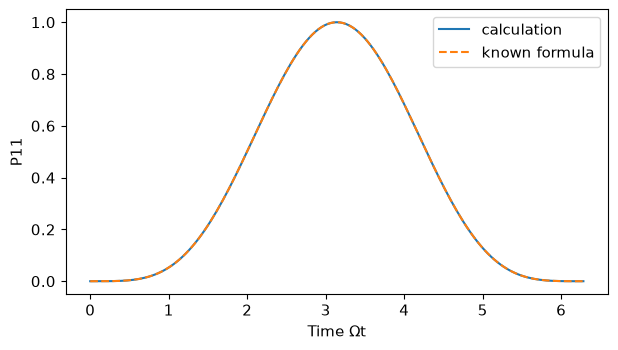

In [4]:
def evolve_dense(H, times):
    energies, vectors = eigh(H)
    initial = np.zeros(H.shape[0], dtype=complex)
    initial[0] = 1
    coefficients = vectors.conj().T @ initial
    states = []
    for t in times:
        state = vectors @ (np.exp(-1j * energies * t) * coefficients)
        states.append(state)
    return np.array(states)

times = np.linspace(0, 2*np.pi, 161)
free = evolve_dense(two_atom_H(0), times)
P11 = abs(free[:, 3])**2
assert np.max(abs(P11-np.sin(times/2)**4)) < 1e-12
assert np.max(abs(np.sum(abs(free)**2, axis=1)-1)) < 1e-12
plt.plot(times, P11, label="calculation")
plt.plot(times, np.sin(times/2)**4, "--", label="known formula")
plt.xlabel("Time Ωt"); plt.ylabel("P11"); plt.legend(); plt.show()

## Foundations part 3 — the Qiskit baseline
The general model is printed below so it is available to inspect. Its bit-basis matrix builder and its Qiskit Pauli builder express the same physics separately. For model changes, edit `rydberg_model.py`, restart the kernel, and run again.

In [5]:
import inspect
import rydberg_model as model
print(inspect.getsource(model.hamiltonian))
print(inspect.getsource(model.qiskit_hamiltonian))

def hamiltonian(coupling, omega=1.0, delta=0.0):
    """Store only nonzero matrix entries so larger examples fit in memory."""
    number = len(coupling)
    occupied = occupations(number)
    labels = np.arange(2**number)
    energy = -delta * occupied.sum(axis=1).astype(float)
    for i in range(number):
        for j in range(i + 1, number):
            energy += coupling[i, j] * occupied[:, i] * occupied[:, j]
    rows, columns = [], []
    for i in range(number):
        # XOR flips atom i, e.g. 000 becomes 001 when i = 0.
        rows.extend(labels)
        columns.extend(labels ^ (1 << i))
    values = np.full(len(rows), omega / 2)
    drive = coo_matrix((values, (rows, columns)), shape=(2**number, 2**number))
    return drive.tocsr() + diags(energy, format="csr")

def qiskit_hamiltonian(coupling, omega=1.0, delta=0.0):
    """Build the same H independently with Qiskit: n = (I - Z)/2."""
    from qiskit.quantum_info import SparsePauliOp
    number = len(coupling)
    terms = [("

Maximum Qiskit versus manual amplitude difference: 4.1920582543206535e-15


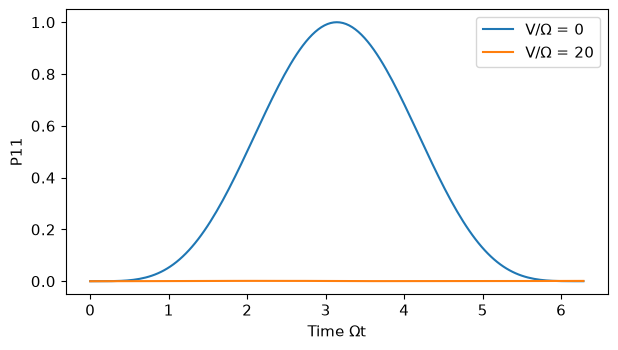

In [6]:
coupling = model.interactions(model.chain(2), 20)
qiskit_states = np.array([model.qiskit_exact_state(coupling, t) for t in times])
manual_states = evolve_dense(two_atom_H(20), times)
error = np.max(abs(qiskit_states-manual_states))
assert error < 1e-10
print("Maximum Qiskit versus manual amplitude difference:", error)
plt.plot(times, abs(free[:,3])**2, label="V/Ω = 0")
plt.plot(times, abs(qiskit_states[:,3])**2, label="V/Ω = 20")
plt.xlabel("Time Ωt"); plt.ylabel("P11"); plt.legend(); plt.show()

**Explain aloud:** increasing $V$ raises the energy of the doubly excited state and makes it harder to excite on resonance. This is Rydberg blockade. The laser is still driving the atoms; blockade does not mean they stop evolving.

## Foundations part 4 — entanglement beyond A Level
For a pure two-atom state, arrange amplitudes as a 2 by 2 matrix $A$. The reduced density matrix of the row subsystem is $AA^\dagger$. Its eigenvalues give the entropy. A Bell state gives 1 bit; a product of two superpositions gives 0. The full pure state has zero entropy in both cases.

In [7]:
def two_atom_entropy(state):
    A = state.reshape(2, 2)
    rho = A @ A.conj().T
    eigenvalues = np.linalg.eigvalsh(rho)
    nonzero = eigenvalues[eigenvalues > 1e-14]
    return -np.sum(nonzero*np.log2(nonzero))

bell = np.array([1,0,0,1], dtype=complex)/np.sqrt(2)
product = np.ones(4, dtype=complex)/2
assert abs(two_atom_entropy(bell)-1) < 1e-12
assert abs(two_atom_entropy(product)) < 1e-12
print("Bell state entropy:", two_atom_entropy(bell))
print("Product state entropy:", two_atom_entropy(product))
qc = QuantumCircuit(2)
qc.h(0); qc.cx(0, 1)
assert abs(np.vdot(bell, Statevector.from_instruction(qc).data)) > 1-1e-12
print(qc.draw(output="text"))

Bell state entropy: 1.0
Product state entropy: -0.0
     ┌───┐     
q_0: ┤ H ├──■──
     └───┘┌─┴─┐
q_1: ─────┤ X ├
          └───┘


The Bell circuit is a mathematical control for entanglement, not a hardware proposal. A 50:50 classical mixture of 00 and 11 would have the same measurement counts but no entanglement. The statevector retains the phase information that counts omit.

## Foundations part 5 — gate steps and a controlled modification
The split circuit alternates laser and energy terms. More steps should improve agreement with direct evolution. The printed error is $1-|\langle\psi_{exact}|\psi_{step}\rangle|^2$, so smaller is better.

In [8]:
# Compare the circuit against an independent dense SciPy evolution.
coupling = model.interactions(model.chain(4), 5)
for detuning in [-1.3, 0., 1.3]:
    H = model.hamiltonian(coupling, delta=detuning).toarray()
    target = evolve_dense(H, [1.0])[0]
    errors = []
    for steps in [10, 20, 40, 80]:
        state = Statevector.from_instruction(model.stepped_circuit(coupling, 1, steps, delta=detuning)).data
        error = max(0., 1-abs(np.vdot(target, state))**2)
        errors.append(error)
    assert all(errors[i+1] < errors[i] for i in range(3))
    print('Detuning', detuning, 'infidelities:', errors)

Detuning -1.3 infidelities: [np.float64(1.7065576989105935e-05), np.float64(1.0458220306430732e-06), np.float64(6.504786087546677e-08), np.float64(4.0606336071391524e-09)]
Detuning 0.0 infidelities: [np.float64(1.3011165730048013e-05), np.float64(8.071847540369603e-07), np.float64(5.0356898428916e-08), np.float64(3.1459159721691776e-09)]


Detuning 1.3 infidelities: [np.float64(7.090888530569828e-06), np.float64(4.410573388735628e-07), np.float64(2.7533397783940927e-08), np.float64(1.7203742874727368e-09)]


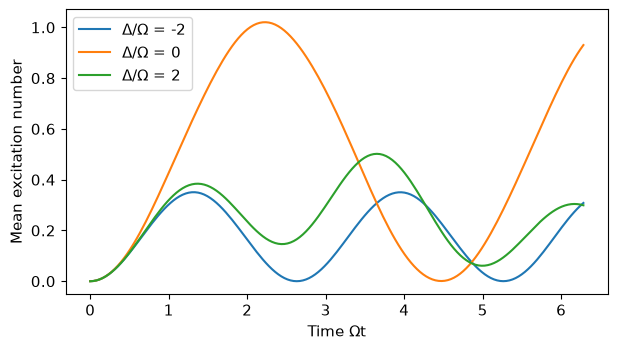

In [9]:
for delta in [-2,0,2]:
    states=evolve_dense(two_atom_H(5,delta), times)
    mean_number=abs(states[:,1])**2+abs(states[:,2])**2+2*abs(states[:,3])**2
    plt.plot(times,mean_number,label=f"Δ/Ω = {delta}")
plt.xlabel("Time Ωt"); plt.ylabel("Mean excitation number")
plt.legend(); plt.show()

Only detuning changed. Positive detuning lowers excitation energy in our convention, but excitation at one particular time need not increase monotonically: these are oscillating states, not equilibrated ground states.

## Foundations part 6 — a spin diagram
A pixel gives a site's excitation probability at a given time. It is not a photograph of one measured configuration. Open ends have fewer nearby neighbours.

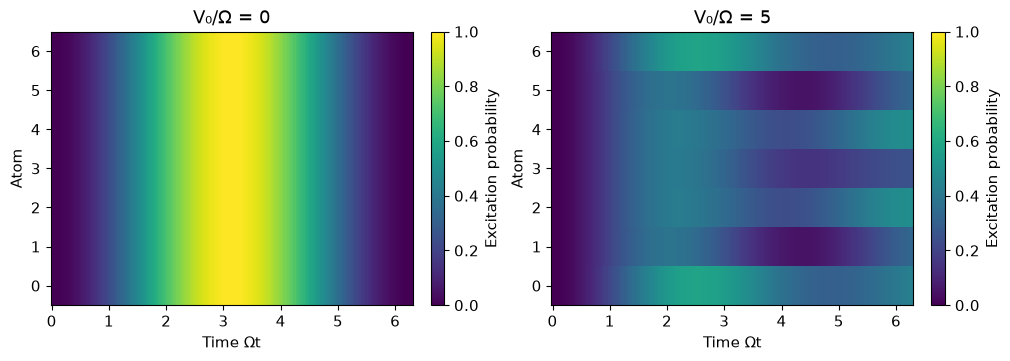

In [10]:
fig,axes=plt.subplots(1,2,figsize=(10,3.5),constrained_layout=True)
for ax,strength in zip(axes,[0,5]):
    H=model.hamiltonian(model.interactions(model.chain(7),strength))
    states=model.evolve(H,times)
    populations=model.excitation_probabilities(states,7)
    im=ax.pcolormesh(times,np.arange(7),populations.T,vmin=0,vmax=1,shading="auto")
    ax.set(title=f"V₀/Ω = {strength}",xlabel="Time Ωt",ylabel="Atom")
    fig.colorbar(im,ax=ax,label="Excitation probability")
plt.show()

## Interaction experiments part 1 — compare blockade fairly
Keep the same initial state, detuning and time interval. Compare a time mean, rather than selecting a favourable moment separately for each interaction. With $V=0$, the exact mean over $0\leq t\leq2\pi$ is 3/8.

In [11]:
scan_times=np.linspace(0,2*np.pi,801)
blockade=[]
for strength in [0,.5,1,2,5,10,20,40]:
    states=evolve_dense(two_atom_H(strength),scan_times)
    pair=abs(states[:,3])**2
    mean=np.trapezoid(pair,scan_times)/(2*np.pi)
    blockade.append([strength,mean,pair.max()])
    print(f"V/Ω={strength:4g}  mean P11={mean:.6f}  sampled peak={pair.max():.6f}")
assert abs(blockade[0][1]-3/8)<1e-12
assert blockade[6][1]<.001

V/Ω=   0  mean P11=0.375000  sampled peak=1.000000
V/Ω= 0.5  mean P11=0.327608  sampled peak=0.853731
V/Ω=   1  mean P11=0.197158  sampled peak=0.563417
V/Ω=   2  mean P11=0.070675  sampled peak=0.184111
V/Ω=   5  mean P11=0.009771  sampled peak=0.025542
V/Ω=  10  mean P11=0.002376  sampled peak=0.005685
V/Ω=  20  mean P11=0.000590  sampled peak=0.001332
V/Ω=  40  mean P11=0.000147  sampled peak=0.000323


## Interaction experiments part 2 — defects with a definition
An isolated atom has every coupling to it set to zero, while its laser remains on. This is an ideal mathematical control. A physical vacancy or a moved atom would need a different model. The second control removes ALL couplings across a chosen cut.

Intact at Ωt=2: 0.9450433709851065 0.7804704688493681
Atom 2 isolated at Ωt=2: -6.406853007629837e-16 0.005234124784703708
Halves disconnected at Ωt=2: 0.8503403339409552 -2.5627412030519365e-15


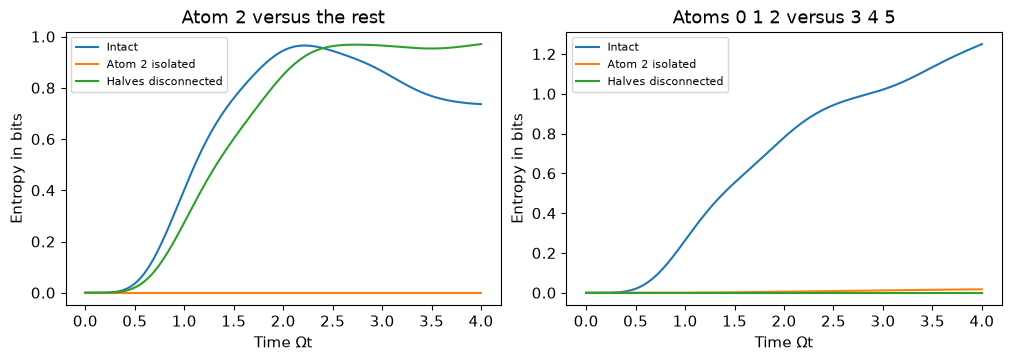

In [12]:
defect_times=np.linspace(0,4,161)
cases={"Intact":model.interactions(model.chain(6),5),
       "Atom 2 isolated":model.interactions(model.chain(6),5,isolated=2),
       "Halves disconnected":model.interactions(model.chain(6),5,split=[0,1,2])}
fig,axes=plt.subplots(1,2,figsize=(10,3.5),constrained_layout=True)
for name,coupling in cases.items():
    states=model.evolve(model.hamiltonian(coupling),defect_times)
    single=np.array([model.entropy(s,[2]) for s in states])
    half=np.array([model.entropy(s,[0,1,2]) for s in states])
    axes[0].plot(defect_times,single,label=name)
    axes[1].plot(defect_times,half,label=name)
    print(name,"at Ωt=2:",single[80],half[80])
    if name=="Atom 2 isolated": assert np.max(abs(single))<1e-10
    if name=="Halves disconnected": assert np.max(abs(half))<1e-10
for ax,title in zip(axes,["Atom 2 versus the rest","Atoms 0 1 2 versus 3 4 5"]):
    ax.set(title=title,xlabel="Time Ωt",ylabel="Entropy in bits"); ax.legend(fontsize=8)
plt.show()

**Check your understanding:** why is the half-chain entropy not exactly zero when only atom 2 is isolated? Atoms elsewhere still interact across the cut through the long-range tail. Also, a disconnected atom can be in a superposition without being entangled.

## Interaction experiments part 3 — geometry and the cut
All arrays have four atoms and minimum spacing 1. The square and rectangle use labels 0,1 on the bottom row and 2,3 on the top. Keeping {0,1} compares the two rows; keeping {0,2} compares the two columns.

In [13]:
shapes={"Chain":model.chain(4),
        "Square":np.array([[0,0],[1,0],[0,1],[1,1]]),
        "Rectangle":np.array([[0,0],[1,0],[0,2],[1,2]])}
for name,positions in shapes.items():
    states=model.evolve(model.hamiltonian(model.interactions(positions,5)),defect_times)
    S01=model.entropy(states[80],[0,1])
    S02=model.entropy(states[80],[0,2])
    print(name,"at Ωt=2:",S01,S02)
    if name=="Square": assert abs(S01-S02)<1e-10
print("A separation of 2a gives an interaction",1/2**6,"of that at a.")

Chain at Ωt=2: 0.7504911392820303 1.5157316415170725
Square at Ωt=2: 1.3652378291096945 1.3652378291096945


Rectangle at Ωt=2: 0.007423301725025517 1.8757309570357097
A separation of 2a gives an interaction 0.015625 of that at a.


A directional entropy belongs to a partition of the whole state, not to an arrow attached to an atom. The chain's {0,2} partition alternates sites and is not a second spatial direction. This comparison changes the whole distance network; it does not keep total coupling fixed.

## Interaction experiments part 4 — larger systems
This benchmark runs actual time evolution, but excludes plotting and entropy. A single timing is only a rough performance observation. 14 is a tested size, not the maximum possible size.

In [14]:
from time import perf_counter
for number in [4,6,8,10,12,14]:
    H=model.hamiltonian(model.interactions(model.chain(number),5))
    start=perf_counter()
    states=model.evolve(H,np.linspace(0,1,21))
    elapsed=perf_counter()-start
    norm_error=np.max(abs(np.sum(abs(states)**2,axis=1)-1))
    assert norm_error<1e-10
    print(number,"atoms;",2**number,"amplitudes;",round(elapsed,4),"seconds;",
          round(states.nbytes/2**20,3),"MiB for 21 saved states")

4 atoms; 16 amplitudes; 0.0049 seconds; 0.005 MiB for 21 saved states
6 atoms; 64 amplitudes; 0.0034 seconds; 0.021 MiB for 21 saved states
8 atoms; 256 amplitudes; 0.0066 seconds; 0.082 MiB for 21 saved states
10 atoms; 1024 amplitudes; 0.014 seconds; 0.328 MiB for 21 saved states
12 atoms; 4096 amplitudes; 0.0394 seconds; 1.312 MiB for 21 saved states


14 atoms; 16384 amplitudes; 0.1002 seconds; 5.25 MiB for 21 saved states


## Ground states and open ends
The dynamics examples evolve a chosen initial state. A ground-state calculation instead finds the lowest-energy eigenvector. The saved map below uses eight atoms. Its small gap and reduced alternating imbalance cannot identify a bulk transition.

Compare both odd and even lengths. In an even open chain, both ends being excited competes with a perfectly alternating pattern. A superposition of configurations containing a 00 bond can have strong local exclusion but reduced global alternating imbalance. The [results and limitations](../docs/RESULTS_AND_LIMITS.md) examine this explicitly.

In [15]:
from phase_diagram_bridge import ground_point
print(inspect.getsource(ground_point))
for delta in [-3,0,3,7]:
    row,state,H=ground_point(8,8,delta)
    print("Δ/Ω",delta,"density",round(row["density"],4),
          "gap/Ω",round(row["gap_over_omega"],4))

def ground_point(number, strength, delta, nearest_only=False):
    coupling = interactions(chain(number), strength)
    if nearest_only:
        for i in range(number):
            for j in range(number):
                if abs(i-j) > 1:
                    coupling[i,j] = 0
    H = hamiltonian(coupling, delta=delta)
    # A fixed starting vector makes the iterative calculation reproducible.
    # It contains both reflection symmetries, unlike a symmetric all-ones vector.
    rng = np.random.default_rng(218)
    energies, vectors = eigsh(H, k=2, which="SA", tol=1e-11,
                             v0=rng.normal(size=H.shape[0]))
    order = np.argsort(energies)
    energies, vectors = energies[order], vectors[:, order]
    state = vectors[:,0]
    bits = occupations(number)
    weights = abs(state)**2
    density = float(weights @ bits.sum(axis=1) / number)
    # Squaring before averaging detects either alternating pattern.
    # This occupation imbalance equals 1 for even ideal pattern

The old diagnostic $M^2=\langle[(2/N)\sum_i(-1)^i n_i]^2\rangle$ equals one for ideal alternating patterns only when N is even. For odd N its two ideal values are $(1+1/N)^2$ and $(1-1/N)^2$.

The comparison now also uses $S^2=\langle[(1/N)\sum_i(-1)^i(2n_i-1)]^2\rangle$, which gives one for either ideal pattern at any N. Both have nonzero finite backgrounds. Normalisation does not remove physical boundary effects or turn either diagnostic into a phase classifier.

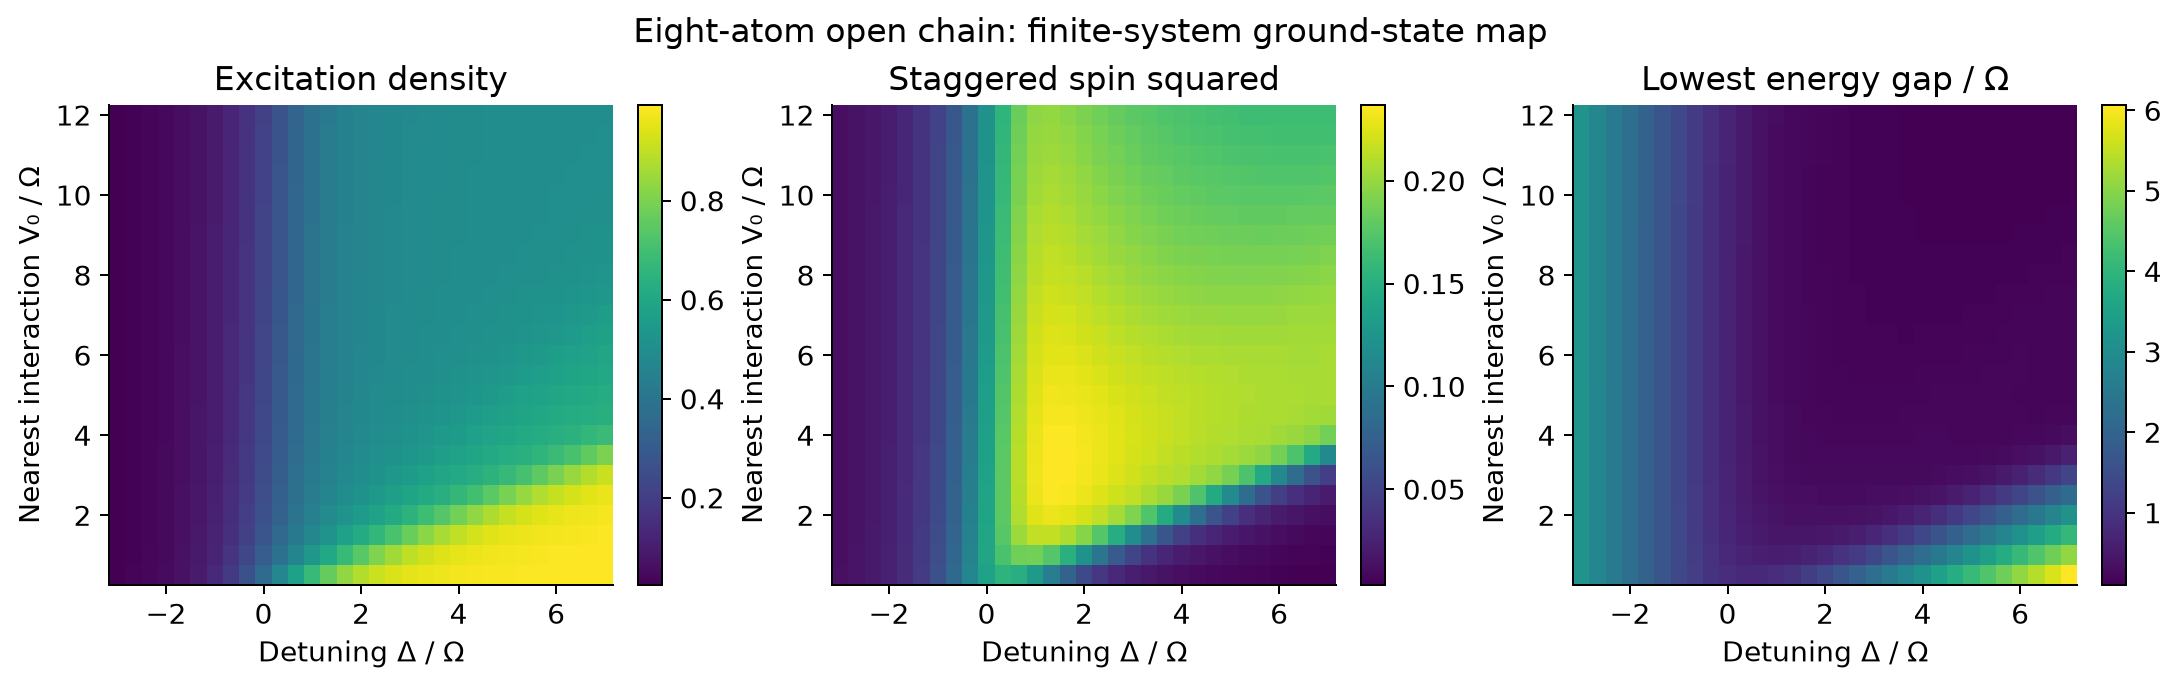

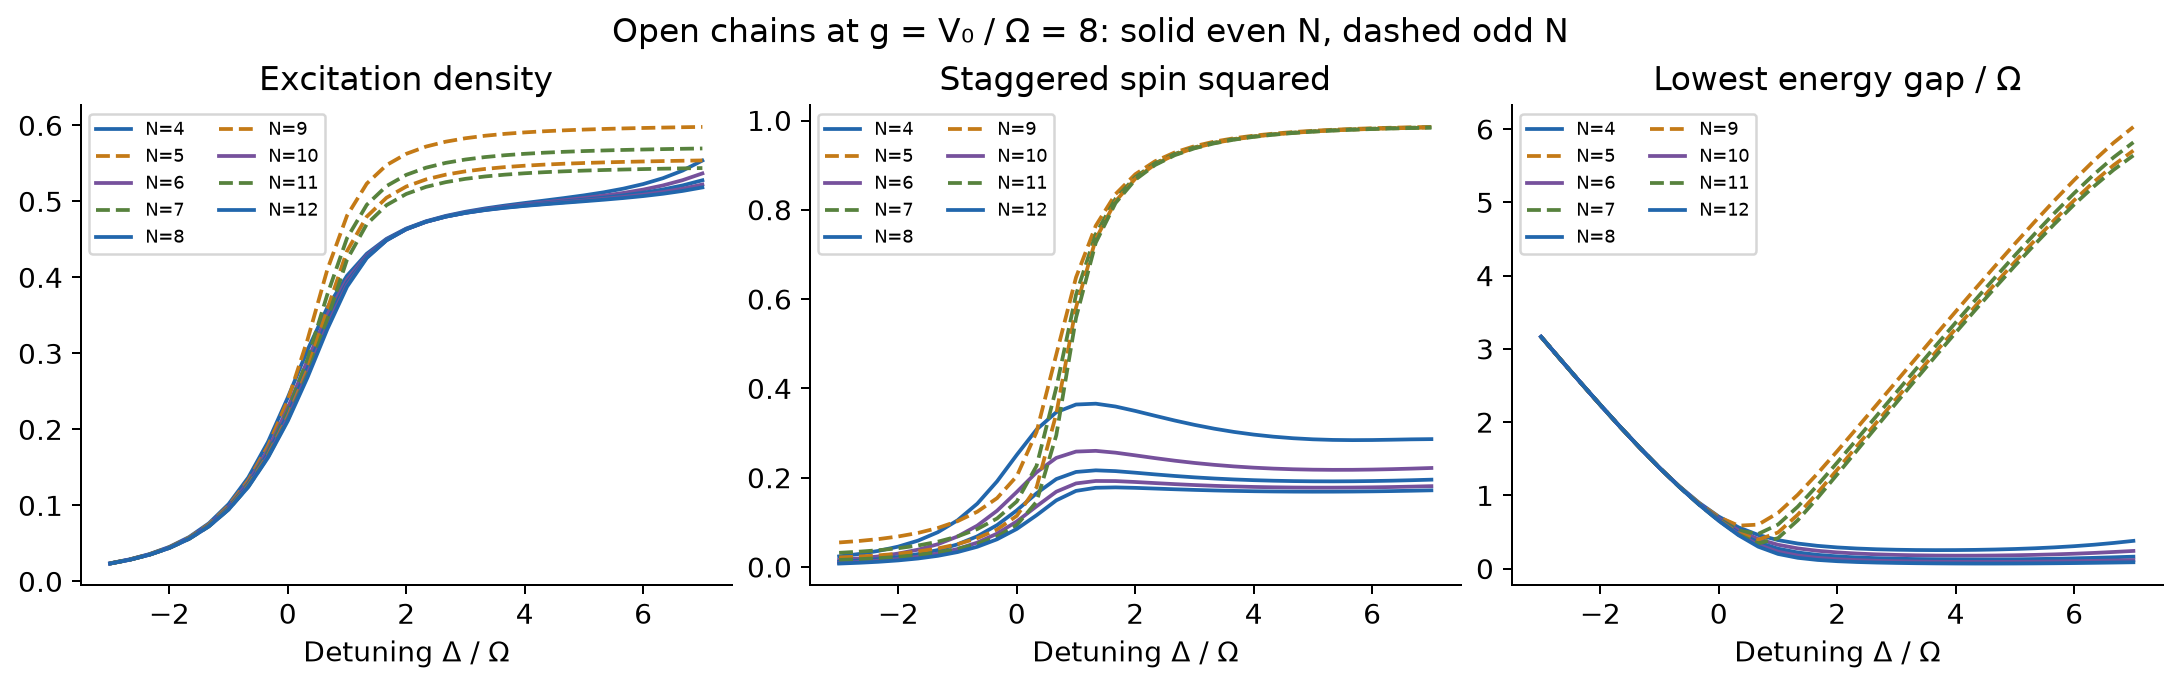

Saved run checks: {'maximum_eigenpair_residual': 3.6727004034952976e-10, 'dense_sparse_energy_and_gap_error': 2.3092638912203256e-14, 'free_density_analytic_error': 0.0, 'free_cut_entropy': 9.61027951144475e-16, 'hellmann_feynman_error': 1.3408900656486367e-09}
Solid lines are even N; dashed lines are odd N. Compare each family separately.


In [16]:
# Read the delivered results without regenerating or replacing any file.
import json
from IPython.display import Image, display
phase_results = json.loads(Path('results/phase_bridge_summary.json').read_text())
display(Image(filename='figures/09_finite_chain_map.png'))
display(Image(filename='figures/10_size_comparison.png'))
print('Saved run checks:', phase_results['checks'])
print('Solid lines are even N; dashed lines are odd N. Compare each family separately.')

## Explain it yourself
1. Set V=0. Why does the interaction term disappear, and why is the cut entropy zero?
2. If distance doubles, does the interaction halve? Calculate the correct factor.
3. Why does a Bell-state histogram alone fail to prove entanglement?
4. What stays unchanged in the blockade scan?
5. Why is an eight-atom colour map insufficient to claim a quantum spin liquid?
6. Explain one numerical check without saying only “the code ran”.

### Answer guide
1. The Hamiltonian separates into independent single-atom terms. A product initial state remains a product.
2. The interaction is multiplied by 1/64 because it is proportional to distance to the power -6.
3. A classical 50:50 mixture of 00 and 11 has the same probabilities but different coherences.
4. The initial state, laser strength, detuning, geometry and comparison interval.
5. It is small, one-dimensional, and lacks the geometry, size checks and nonlocal diagnostics needed for that claim.
6. Examples: V=0 agrees with sin²(t/2); two independent Hamiltonian constructions agree; residual Hψ−Eψ is small.

### Reproduction exercise
Predict the difference between N=8 and N=9 before opening [Finite Chain Study](Finite_Chain_Study.ipynb). Reproduce that comparison and record your own explanation. The rectangle exercise remains optional background. The supplied parity scan was generated with AI assistance; rerunning it is reproduction, not a claim of first discovery.

### Sources
Model and experiment: [Bernien et al. 2017](https://arxiv.org/abs/1707.04344).
Starting workflow: [Qiskit Cold Atom tutorial](https://qiskit-community.github.io/qiskit-cold-atom/tutorials/09_ryberg_dynamics.html), adapted to installed Qiskit rather than run unchanged.
Implementation: [IBM Qiskit documentation](https://quantum.cloud.ibm.com/docs/en/api/qiskit/quantum_info).
For kagome context see [Samajdar et al. 2021](https://pmc.ncbi.nlm.nih.gov/articles/PMC7848540/) and [Semeghini et al. 2021](https://arxiv.org/abs/2104.04119). Neither kagome study is reproduced here.
